In [ ]:
!pip install tensorflow
!pip install importlib_resources

In [ ]:
import os
import tensorflow as tf
import tensorflow_datasets as tfds

data_dir = '/content/drive/MyDrive/tensorflow_datasets'

if not os.path.exists(data_dir):
  os.makedirs(data_dir, exist_ok=True)

train_ds, validation_ds, test_ds = tfds.load(
  'cats_vs_dogs',
  split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
  shuffle_files=True,
  as_supervised=True,
  data_dir=data_dir)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/drive/MyDrive/tensorflow_datasets/cats_vs_dogs/incomplete.KKRXRO_4.0.1/cats_vs_dogs-train.t…

Dataset cats_vs_dogs downloaded and prepared to /content/drive/MyDrive/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


In [ ]:
names = ['training', 'validation', 'test']
for i, ds in enumerate((train_ds, validation_ds, test_ds)):
  count = 0
  for _ in ds:
    count += 1
  print('Number of', names[i], f'samples: {count}')


Number of training samples: 18610
Number of validation samples: 2326
Number of test samples: 2326


In [ ]:
import matplotlib.pyplot as plt

def visualize_samples(dataset, num_samples=10, buffer_sizesize=1000):
  num_rows = num_samples // 5 + (num_samples % 5 != 0)
  plt.figure(figsize=(15, 3 * num_rows))
  dataset = dataset.shuffle(buffer_size=buffer_sizesize).take(num_samples)
  for i, (image, label) in enumerate(dataset):
    plt.subplot(num_rows, 5, i + 1)
    plt.imshow(image)
    plt.title(f'label: {label.numpy()}')
    plt.axis('off')
  plt.show()


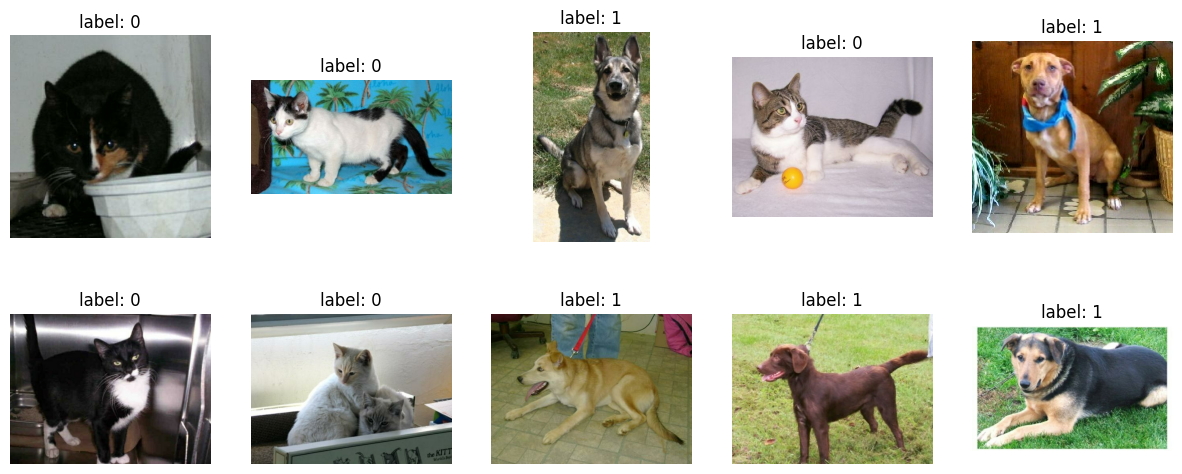

In [ ]:
visualize_samples(dataset=validation_ds, num_samples=10, buffer_sizesize=2326)


In [ ]:
IMG_SIZE = 128

def preprocess(image, label):
  image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
  image = tf.cast(image, tf.float32) / 255.0
  return image, label


In [ ]:
BATCH_SIZE = 32

train_ds_processed = train_ds.map(preprocess,
                                  num_parallel_calls=tf.data.AUTOTUNE)
train_ds_processed = train_ds_processed.cache()
#train_ds_processed = train_ds_processed.shuffle(1000)
train_ds_processed = train_ds_processed.batch(BATCH_SIZE)
train_ds_processed = train_ds_processed.prefetch(tf.data.AUTOTUNE)

validation_ds_processed = validation_ds.map(preprocess,
                                            num_parallel_calls=tf.data.AUTOTUNE)
validation_ds_processed = validation_ds_processed.cache()
validation_ds_processed = validation_ds_processed.batch(BATCH_SIZE)
validation_ds_processed = validation_ds_processed.prefetch(tf.data.AUTOTUNE)

test_ds_processed = test_ds.map(preprocess,
                                num_parallel_calls=tf.data.AUTOTUNE)
test_ds_processed = test_ds_processed.cache()
test_ds_processed = test_ds_processed.batch(BATCH_SIZE)
test_ds_processed = test_ds_processed.prefetch(tf.data.AUTOTUNE)


In [ ]:
from keras.models import Sequential
from keras.layers import RandomFlip, RandomRotation, RandomZoom

# Слои аугментации: работают только при обучении (training=True),
# при evaluate / predict автоматически отключаются
data_augmentation = Sequential([
  RandomFlip('horizontal'),   # зеркальное отражение по горизонтали
  RandomRotation(0.05),       # поворот на случайный угол до +-0.05 * 360 = +-18 градусов
  RandomZoom(0.1)],           # случайное изменение масштаба примерно на +-10%
  name='data_augmentation')

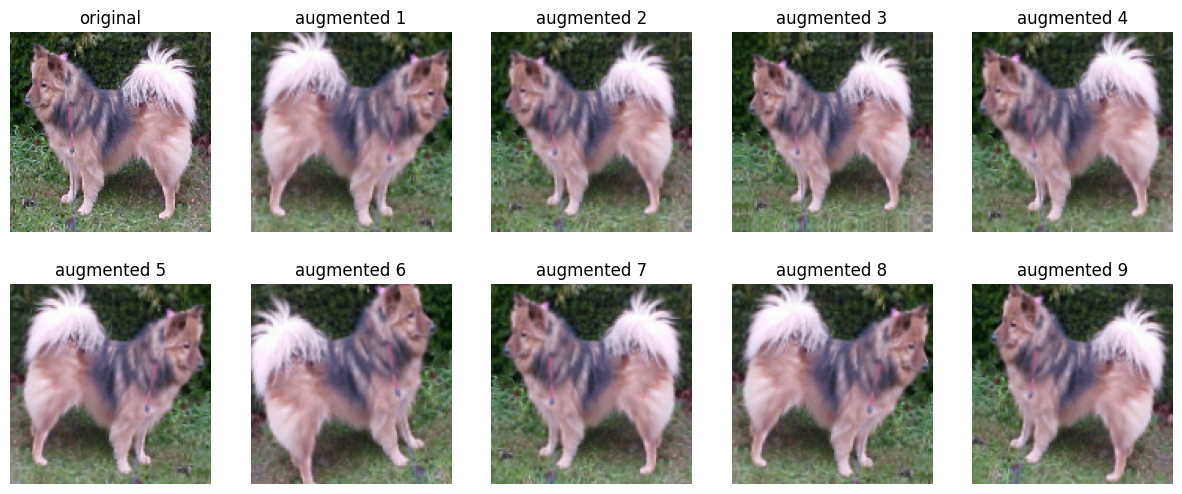

In [ ]:
import numpy as np

# Берём одну картинку из обучающего набора и показываем 10 её аугментированных вариантов
for images, labels in train_ds_processed.take(1):
  sample_image = images[0]

plt.figure(figsize=(15, 6))
plt.subplot(2, 5, 1)
plt.imshow(sample_image)
plt.title('original')
plt.axis('off')

for i in range(9):
  augmented = data_augmentation(tf.expand_dims(sample_image, axis=0), training=True)
  plt.subplot(2, 5, i + 2)
  plt.imshow(np.asarray(augmented[0]))
  plt.title(f'augmented {i + 1}')
  plt.axis('off')
plt.show()

In [ ]:
import keras
from keras.layers import Input, Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from keras.models import Sequential

model = Sequential([
  Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
  data_augmentation,
  Conv2D(32, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Conv2D(64, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Conv2D(128, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Flatten(),
  Dense(128, activation='relu'),
  Dropout(0.5),
  Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
  optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy'])


In [ ]:
from keras.callbacks import EarlyStopping, ModelCheckpoint

EPOCHS = 10

history = model.fit(
  train_ds_processed,
  epochs=EPOCHS,
  validation_data=validation_ds_processed,
  callbacks=[
      EarlyStopping(monitor='val_loss', patience=3),
      ModelCheckpoint('/content/drive/MyDrive/Models/best_model_aug.keras',
                      save_best_only=True)])

Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.5844 - loss: 0.6687 - val_accuracy: 0.6724 - val_loss: 0.6109
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.6940 - loss: 0.5822 - val_accuracy: 0.7541 - val_loss: 0.5237
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7540 - loss: 0.5116 - val_accuracy: 0.7842 - val_loss: 0.4626
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7830 - loss: 0.4631 - val_accuracy: 0.8031 - val_loss: 0.4325
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8019 - loss: 0.4338 - val_accuracy: 0.8246 - val_loss: 0.3899
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8153 - loss: 0.4041 - val_accuracy: 0.8280 - val_loss: 0.3799
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.8264 - loss: 0.3894 - val_accuracy: 0.8229 - val_loss: 0.3852
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8397 - loss: 0.3683 - 

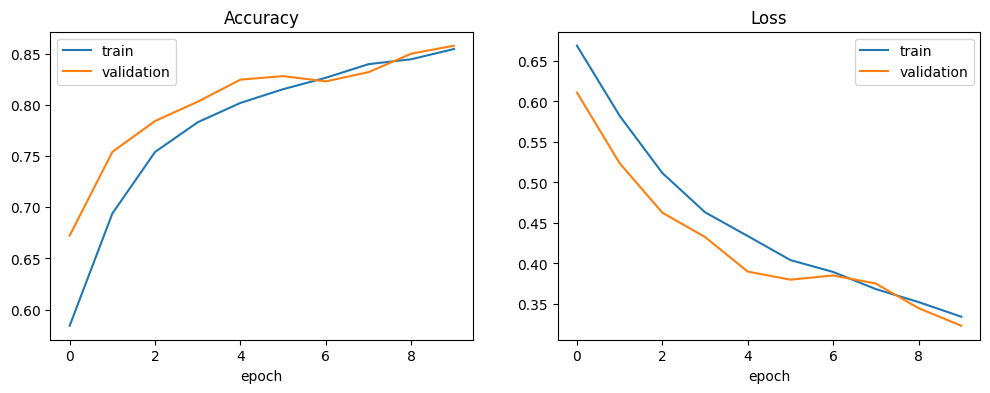

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy')
plt.xlabel('epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss')
plt.xlabel('epoch')
plt.legend()

plt.show()

In [ ]:
from keras.models import load_model

loaded_model = load_model('/content/drive/MyDrive/Models/best_model_aug.keras',
                          compile=False)

loaded_model.compile(
  optimizer='adam',
  loss='binary_crossentropy',
  metrics=['accuracy'])

loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
loss, accuracy = loaded_model.evaluate(test_ds_processed, verbose=False)
print(accuracy)


0.8598452210426331


In [ ]:
# Сравнение с моделью без аугментации (сохранена в исходной работе как best_model.keras)
baseline_path = '/content/drive/MyDrive/Models/best_model.keras'

if os.path.exists(baseline_path):
  baseline_model = load_model(baseline_path, compile=False)
  baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])
  _, baseline_accuracy = baseline_model.evaluate(test_ds_processed, verbose=False)
  print(f'Test accuracy without augmentation: {baseline_accuracy:.4f}')
else:
  print('best_model.keras not found: no baseline to compare with')

print(f'Test accuracy with augmentation:    {accuracy:.4f}')

best_model.keras not found: no baseline to compare with
Test accuracy with augmentation:    0.8598


In [ ]:
def visualize_predictions(dataset_raw, num_samples=10, buffer_sizesize=1000):
  num_rows = num_samples // 5 + (num_samples % 5 != 0)
  plt.figure(figsize=(15, 3 * num_rows))

  visual_dataset = dataset_raw.shuffle(buffer_size=buffer_sizesize)
  visual_dataset = visual_dataset.take(num_samples).map(preprocess)

  images_to_predict = []
  labels_to_display = []

  for image, label in visual_dataset:
      images_to_predict.append(image)
      labels_to_display.append(label.numpy())

  batch_for_prediction = tf.stack(images_to_predict)

  all_predictions = loaded_model.predict(batch_for_prediction, verbose=False)

  for i in range(num_samples):
    plt.subplot(num_rows, 5, i + 1)
    plt.imshow(images_to_predict[i].numpy())
    probability = all_predictions[i][0]
    predicted_class = 'dog' if probability >= 0.5 else 'cat'
    true_class = 'dog' if labels_to_display[i] == 1 else 'cat'
    plt.title(f'tl: {true_class} pl: {predicted_class}')
    plt.axis('off')

  plt.show()


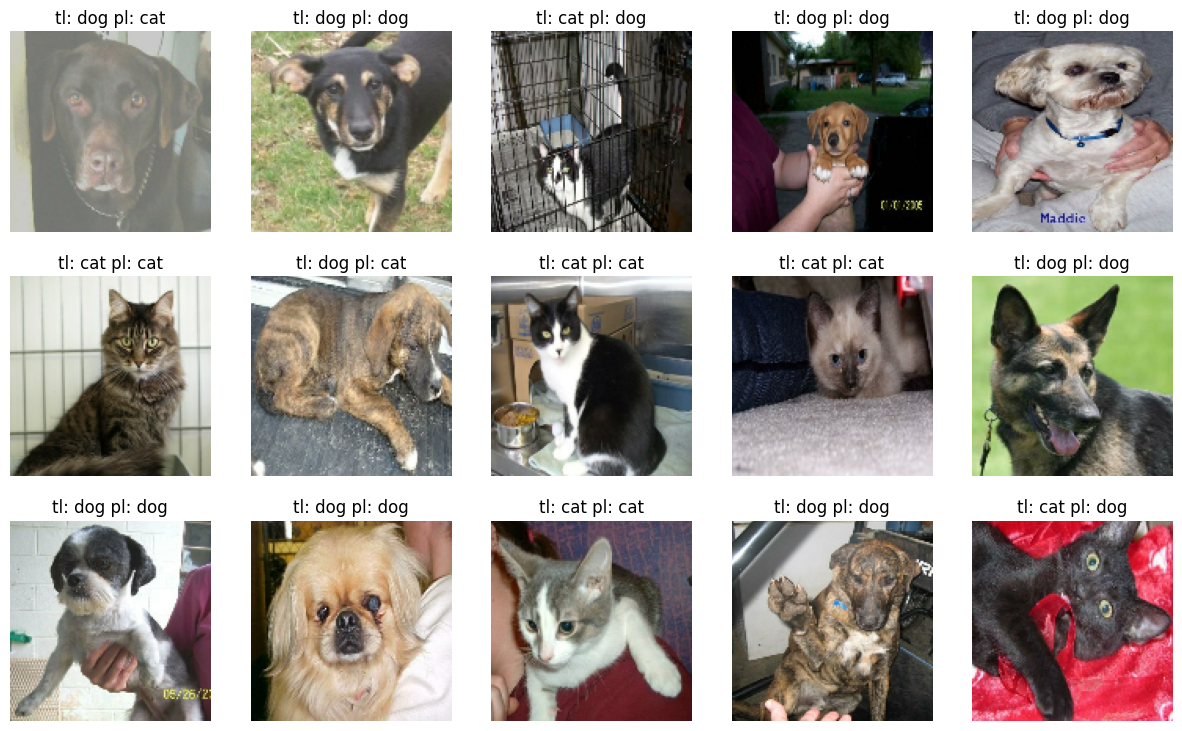

In [ ]:
visualize_predictions(dataset_raw=test_ds,
                      num_samples=15, buffer_sizesize=2326)

In [ ]:
import io
from google.colab import files

def predict_uploaded_image(model, img_size=128):
  for filename, content in files.upload().items():
    image = tf.image.decode_image(content, channels=3)
    image = tf.image.resize(image, (img_size, img_size))
    image = tf.cast(image, tf.float32) / 255.0
    image_batch = tf.expand_dims(image, axis=0)

    prediction = model.predict(image_batch, verbose=False)
    probability = prediction[0][0]
    predicted_class = 'Dog' if probability >= 0.5 else 'Cat'

    plt.figure(figsize=(6, 6))
    plt.imshow(image.numpy())
    title = f'Predicted class: {predicted_class}\n'
    title += f'(Probability: {probability:.2f})'
    plt.title(title)
    plt.axis('off')
    plt.show()


In [ ]:
if 'loaded_model' in locals() or 'loaded_model' in globals():
  predict_uploaded_image(loaded_model, IMG_SIZE)
else:
  print('Model not found. Please ensure it is loaded.')
